# PDAN8412 POE – Part 3: CNN Facial Recognition
**Student:** Adivhaho Randima (ST10128395)
**Scenario:** The book press wants a facial-recognition system at its premises to identify known people from camera images.
**Dataset:** Labeled Faces in the Wild (LFW) – Huang et al. (2007)

**Notebook flow**
1. Setup and data loading
2. Dataset justification and analysis plan
3. Exploratory data analysis (EDA) with Spark
4. Data preparation (subset selection, scaling, split)
5. Baseline CNN – training and evaluation
6. Retrained CNN (augmentation + regularisation) – training and evaluation
7. Model comparison and conclusion

## 1. Setup
Libraries: PySpark for the analysis (required by the brief), TensorFlow/Keras for the CNN, scikit-learn to load LFW and for evaluation metrics.
A fixed random seed is set so results can be reproduced.

In [1]:
import os, sys, glob
# Spark 4.2 needs Java 17/21; use the JDK 17 installed inside this conda env
os.environ['JAVA_HOME'] = glob.glob(os.path.join(sys.prefix, 'jdk', 'jdk-17*'))[0]
os.environ['PATH'] = os.path.join(os.environ['JAVA_HOME'], 'bin') + os.pathsep + os.environ['PATH']
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # avoids an OpenMP clash between TensorFlow and NumPy on Windows

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

spark = (SparkSession.builder
         .appName("PDAN8412_Part3_CNN")
         .config("spark.driver.memory", "4g")
         .getOrCreate())
def to_pandas(sdf_):
    """Collect a small Spark DataFrame to pandas without Arrow (Arrow's toPandas crashes alongside TensorFlow on Windows)."""
    return pd.DataFrame([r.asDict() for r in sdf_.collect()], columns=sdf_.columns)

print("Spark:", spark.version, "| TensorFlow:", tf.__version__)

Spark: 4.2.0 | TensorFlow: 2.21.0


### 1.1 Load the full LFW dataset
`fetch_lfw_people` downloads LFW (about 200 MB, first run only) and caches it in `~/scikit_learn_data`.
`min_faces_per_person=0` keeps **every** image so EDA covers the full dataset. `resize=0.5` gives 62 × 47 greyscale images, which is enough detail for a CNN and keeps training time manageable on a laptop.

In [2]:
lfw_all = fetch_lfw_people(min_faces_per_person=0, resize=0.5, color=False)
X_all = lfw_all.images          # (n_images, 62, 47), pixel values already scaled 0-1
y_all = lfw_all.target
names_all = lfw_all.target_names

print("Images:", X_all.shape[0])
print("Image size (h x w):", X_all.shape[1:])
print("Distinct people:", len(names_all))

Images: 13233
Image size (h x w): (62, 47)
Distinct people: 5749


## 2. Dataset justification
- **Size:** LFW holds 13,233 labelled face images of 5,749 people, which meets the brief's minimum of 10,000 records.
- **Relevance:** The images are real-world photos (different lighting, pose, expression and background), much like camera frames at a building entrance – a better test than studio-posed photos.
- **Labels:** Every image is tagged with the person's name, so it supports supervised classification ("who is this?").
- **Recognised benchmark:** LFW is a standard face-recognition benchmark (Huang et al., 2007), so results can be compared with published work.
- **Ethics/POPIA:** The images are of public figures collected from news photos and released for research. A real deployment at the publisher would need staff consent and a POPIA-compliant processing purpose, because facial images are biometric (special personal) information.

**Limitation (handled in Section 4):** most people have only one image, and a classifier cannot learn a person from one photo. Training therefore uses the people with enough images, while EDA uses all 13,233.

**Data quality and common pitfalls checked:**
- *Class imbalance:* most people have one photo while a few have hundreds. If this isn't handled, a model can score well just by predicting the frequent people. This is handled by subset selection, a stratified split, macro F1 and mild class weights.
- *Too few images per person:* a person with one photo can't be learned. Only people with at least 20 photos are kept.
- *Uncontrolled conditions:* lighting, pose, expression and occlusions (glasses, hands) vary. The EDA measures brightness and contrast, and augmentation adds pose and framing variation.
- *Low resolution / greyscale:* 62 × 47 greyscale keeps training feasible on a CPU but loses colour and fine detail. This is a known limitation.
- *Data leakage:* the split is done once, stratified, *before* training, and the test set is only used for the final evaluation.
- *Representation bias:* the dataset's creators warn that many groups are poorly represented in LFW (very few children or people over 80, a relatively small proportion of women, and some ethnicities barely represented), and that LFW alone can't prove software has been thoroughly tested (University of Massachusetts Amherst, n.d.). Accuracy may therefore not transfer to the publisher's staff, and any real system must be re-tested on local data.

## 2.1 Analysis plan
| Step | Plan | Why |
|---|---|---|
| **EDA (Spark)** | Load all 13,233 images. Build a Spark DataFrame of label + pixel statistics (mean, std, min, max). Check missing values, images per person, brightness/contrast spread, and view sample faces. | Confirms the data is clean and shows imbalance and lighting variation, which shape the training choices. |
| **Feature / sample selection** | A CNN learns its own features from raw pixels, so P-value elimination doesn't apply to individual pixels. Selection is done at the **sample/class level**: keep people with ≥ 20 images, use greyscale, resize to 62 × 47 and scale pixels to 0–1. | Gives each class enough examples and keeps the input small and consistent. |
| **Split** | Stratified 70 / 15 / 15 train / validation / test, fixed seed. | Every person appears in every set; the test set stays untouched. |
| **Train – baseline** | 3 × (Conv 3×3 + MaxPool) with 32/64/128 filters → Dense 128 → softmax. Adam (lr 0.001), sparse categorical cross-entropy, batch 32, 30 epochs. | A simple reference model to diagnose against. |
| **Train – retrain** | Same backbone + augmentation (flip, rotation, zoom, shift), dropout 0.3/0.5, L2 1e-4, Dense 256, mild √-balanced class weights, early stopping on val accuracy (patience 15), LR halving on plateau, up to 80 epochs. | Targets the expected weaknesses: overfitting and imbalance. |
| **Evaluate** | Test accuracy, **macro F1** (main metric – treats every person equally), weighted F1, per-person precision/recall, confusion matrix, learning curves, sample predictions; Spark comparison of per-person F1 between models. | Accuracy alone hides poor performance on rare people. |
| **Report** | Short PDF for the client: dataset and quality, EDA findings, how both models were trained, results table and curves, why the retrain helped, deployment recommendations (POPIA). | Required deliverable; kept succinct to avoid the length penalty. |

## 3. Exploratory data analysis with Spark
Each image becomes one row of a Spark DataFrame with its label and simple pixel statistics (mean brightness, contrast/standard deviation, min, max). Spark then does the grouping and aggregation.

In [3]:
flat = X_all.reshape(X_all.shape[0], -1)
meta_pd = pd.DataFrame({
    "image_id": np.arange(len(y_all)),
    "person": names_all[y_all],
    "mean_px": flat.mean(axis=1),
    "std_px": flat.std(axis=1),
    "min_px": flat.min(axis=1),
    "max_px": flat.max(axis=1),
})
sdf = spark.createDataFrame(meta_pd)
sdf.printSchema()
print("Rows in Spark DataFrame:", sdf.count())
sdf.show(5, truncate=False)

root
 |-- image_id: long (nullable = true)
 |-- person: string (nullable = true)
 |-- mean_px: float (nullable = true)
 |-- std_px: float (nullable = true)
 |-- min_px: float (nullable = true)
 |-- max_px: float (nullable = true)

Rows in Spark DataFrame: 13233
+--------+----------------------------+----------+----------+-----------+----------+
|image_id|person                      |mean_px   |std_px    |min_px     |max_px    |
+--------+----------------------------+----------+----------+-----------+----------+
|0       |Tim Curry                   |0.4943406 |0.16539185|0.05620915 |0.94248366|
|1       |Mahmoud Abbas               |0.5025207 |0.11768934|0.009150327|0.90326804|
|2       |Michel Charles Chretien     |0.61982185|0.16813065|0.06405229 |0.8810458 |
|3       |Abid Hamid Mahmud Al-Tikriti|0.36600232|0.20455906|0.024836602|0.81830066|
|4       |Mona Locke                  |0.35497734|0.17711097|0.022222223|0.6810458 |
+--------+----------------------------+----------+--------

### 3.1 Missing values and summary statistics

In [4]:
sdf.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in sdf.columns]).show()
sdf.select("mean_px", "std_px", "min_px", "max_px").describe().show()

+--------+------+-------+------+------+------+
|image_id|person|mean_px|std_px|min_px|max_px|
+--------+------+-------+------+------+------+
|       0|     0|      0|     0|     0|     0|
+--------+------+-------+------+------+------+

+-------+-------------------+-------------------+-------------------+------------------+
|summary|            mean_px|             std_px|             min_px|            max_px|
+-------+-------------------+-------------------+-------------------+------------------+
|  count|              13233|              13233|              13233|             13233|
|   mean| 0.4863934947996555|0.16118401087871767|0.05148843226916055|0.8691976822972938|
| stddev|0.08383776577056591|0.03633500190993076|0.04515035186403673|0.0948554197749104|
|    min|         0.14126036|        0.054398224|                0.0|         0.4248366|
|    max|          0.7775777|         0.31365693|         0.32156864|               1.0|
+-------+-------------------+-------------------+---

### 3.2 Images per person (class distribution)

In [5]:
per_person = (sdf.groupBy("person").count()
                 .withColumnRenamed("count", "n_images")
                 .orderBy(F.desc("n_images")))
per_person.show(15, truncate=False)

dist = (per_person.groupBy("n_images").count()
                  .withColumnRenamed("count", "n_people")
                  .orderBy("n_images"))
one_img = per_person.filter(F.col("n_images") == 1).count()
print(f"People with only 1 image: {one_img} of {per_person.count()}")

for t in [10, 20, 30, 50, 70]:
    sub = per_person.filter(F.col("n_images") >= t)
    print(f">= {t:>2} images: {sub.count():>4} people, "
          f"{sub.agg(F.sum('n_images')).first()[0]:>5} images")

+-------------------------+--------+
|person                   |n_images|
+-------------------------+--------+
|George W Bush            |530     |
|Colin Powell             |236     |
|Tony Blair               |144     |
|Donald Rumsfeld          |121     |
|Gerhard Schroeder        |109     |
|Ariel Sharon             |77      |
|Hugo Chavez              |71      |
|Junichiro Koizumi        |60      |
|Jean Chretien            |55      |
|John Ashcroft            |53      |
|Jacques Chirac           |52      |
|Serena Williams          |52      |
|Vladimir Putin           |49      |
|Luiz Inacio Lula da Silva|48      |
|Gloria Macapagal Arroyo  |44      |
+-------------------------+--------+
only showing top 15 rows
People with only 1 image: 4069 of 5749
>= 10 images:  158 people,  4324 images
>= 20 images:   62 people,  3023 images
>= 30 images:   34 people,  2370 images
>= 50 images:   12 people,  1560 images
>= 70 images:    7 people,  1288 images


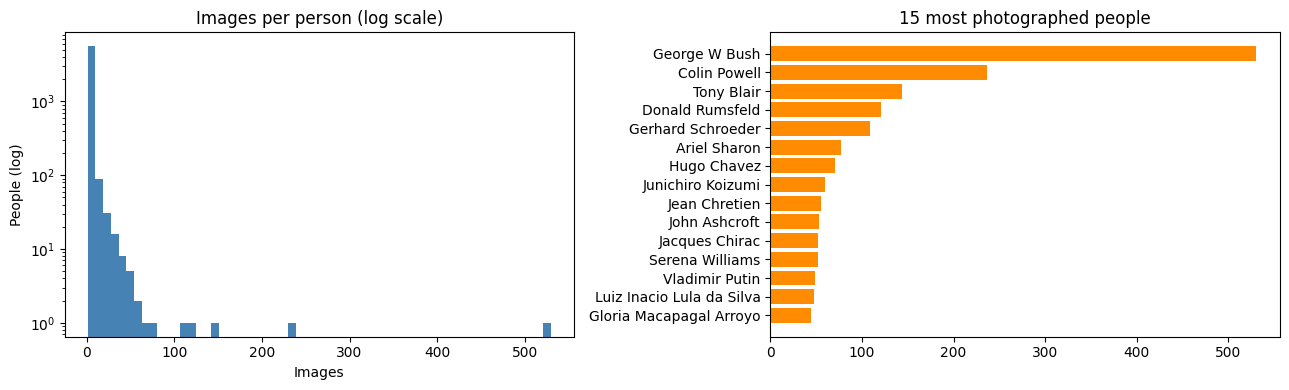

In [6]:
pp = to_pandas(per_person)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(pp["n_images"], bins=60, log=True, color="steelblue")
ax[0].set_title("Images per person (log scale)")
ax[0].set_xlabel("Images"); ax[0].set_ylabel("People (log)")
top = pp.head(15)
ax[1].barh(top["person"][::-1], top["n_images"][::-1], color="darkorange")
ax[1].set_title("15 most photographed people")
plt.tight_layout(); plt.show()

**Observation:** The distribution is extremely skewed. Most people appear once, and a few (e.g. George W. Bush) appear hundreds of times. This drives two decisions: (1) only people with enough images are used for training, and (2) class imbalance must be handled.

### 3.3 Pixel brightness and contrast

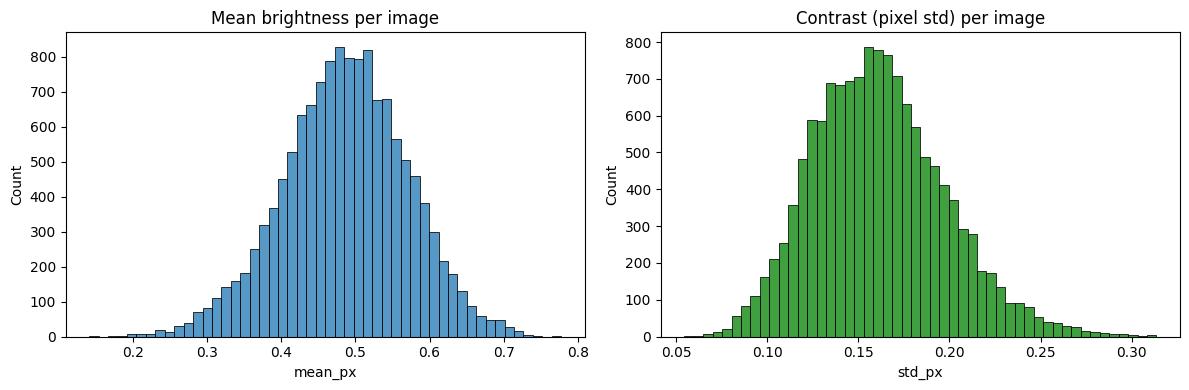

+-----------+-----+
|bright_band|count|
+-----------+-----+
|     normal|12706|
|       dark|  231|
|     bright|  296|
+-----------+-----+



In [7]:
px = to_pandas(sdf.select("mean_px", "std_px"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(px["mean_px"], bins=50, ax=ax[0]); ax[0].set_title("Mean brightness per image")
sns.histplot(px["std_px"], bins=50, ax=ax[1], color="green"); ax[1].set_title("Contrast (pixel std) per image")
plt.tight_layout(); plt.show()

sdf.withColumn("bright_band", F.when(F.col("mean_px") < 0.30, "dark")
                              .when(F.col("mean_px") > 0.65, "bright")
                              .otherwise("normal")) \
   .groupBy("bright_band").count().show()

**Observation:** Brightness and contrast vary from image to image because the photos come from uncontrolled settings. Pixel values are scaled to 0–1 before training, and the retrained model adds random brightness/contrast changes so it copes with lighting differences at an entrance camera.

### 3.4 Sample images

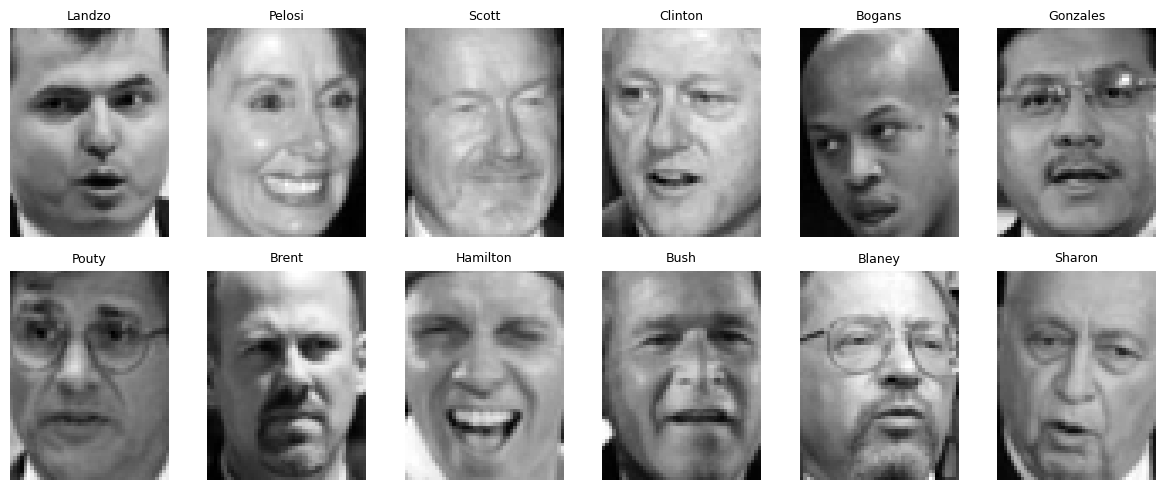

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
idx = np.random.choice(len(X_all), 12, replace=False)
for a, i in zip(axes.ravel(), idx):
    a.imshow(X_all[i], cmap="gray"); a.set_title(names_all[y_all[i]].split()[-1], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Data preparation
### 4.1 Subset selection (feature/sample selection)
For a CNN the "features" are the raw pixels, and the convolution filters learn which patterns matter, so classic feature selection (e.g. P-values) doesn't apply to individual pixels. The main selection decision is therefore **which people (classes)** to include. People with **at least 20 images** are kept. Based on the EDA counts this gives about 62 people and about 3,000 images: enough examples per person to learn, while keeping a realistic number of identities for a staff-recognition system.

In [9]:
MIN_FACES = 20
keep_names = {r["person"] for r in per_person.filter(F.col("n_images") >= MIN_FACES)
                                           .select("person").collect()}
mask = np.isin(names_all[y_all], list(keep_names))
X = X_all[mask]
person = names_all[y_all[mask]]
classes = np.array(sorted(keep_names))
cls_index = {n: i for i, n in enumerate(classes)}
y = np.array([cls_index[p] for p in person])
n_classes = len(classes)
print("Images kept:", len(X), "| Classes:", n_classes)

Images kept: 3023 | Classes: 62


### 4.2 Scaling, reshaping and split
- Pixels are already scaled to 0–1 by scikit-learn (small, consistent input values help gradient descent converge), so no further scaling is needed.
- A channel dimension is added: (62, 47, 1).
- Stratified split **70% train / 15% validation / 15% test**, so every person appears in each set in proportion. The test set is only used at the end.

In [10]:
X = X.astype("float32")[..., np.newaxis]   # scikit-learn already returns pixels scaled to 0-1
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
INPUT_SHAPE = X_train.shape[1:]

Train: (2116, 62, 47, 1) Val: (453, 62, 47, 1) Test: (454, 62, 47, 1)


## 5. Baseline CNN
A small, standard CNN: three convolution + max-pooling blocks that learn edges → facial parts → whole-face patterns, followed by a dense layer and a softmax output (one probability per person).
Loss: sparse categorical cross-entropy. Optimiser: Adam. No augmentation or regularisation. This is the reference point.

In [11]:
def build_baseline():
    m = keras.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model_v1 = build_baseline()
model_v1.summary()
hist_v1 = model_v1.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=30, batch_size=32, verbose=2)
model_v1.save("model_v1_baseline.keras")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 47, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 31, 23, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 15, 11, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 15, 11, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 7, 5, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4480)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         573,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 62)                  │           7,998 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 674,238 (2.57 MB)

 Trainable params: 674,238 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
67/67 - 12s - 178ms/step - accuracy: 0.1621 - loss: 3.7833 - val_accuracy: 0.1744 - val_loss: 3.6873
Epoch 2/30
67/67 - 5s - 76ms/step - accuracy: 0.1753 - loss: 3.6845 - val_accuracy: 0.1722 - val_loss: 3.6611
Epoch 3/30
67/67 - 6s - 89ms/step - accuracy: 0.1838 - loss: 3.5107 - val_accuracy: 0.1921 - val_loss: 3.3185
Epoch 4/30
67/67 - 5s - 75ms/step - accuracy: 0.2566 - loss: 3.1252 - val_accuracy: 0.2980 - val_loss: 2.9356
Epoch 5/30
67/67 - 6s - 92ms/step - accuracy: 0.3563 - loss: 2.5950 - val_accuracy: 0.3885 - val_loss: 2.5514
Epoch 6/30
67/67 - 9s - 132ms/step - accuracy: 0.4716 - loss: 2.0628 - val_accuracy: 0.4592 - val_loss: 2.2648
Epoch 7/30
67/67 - 8s - 120ms/step - accuracy: 0.5789 - loss: 1.6073 - val_accuracy: 0.5254 - val_loss: 1.9876
Epoch 8/30
67/67 - 8s - 125ms/step - accuracy: 0.6640 - loss: 1.2419 - val_accuracy: 0.5563 - val_loss: 1.9572
Epoch 9/30
67/67 - 6s - 84ms/step - accuracy: 0.7198 - loss: 0.9994 - val_accuracy: 0.6049 - val_loss: 1.8286
Epoch

### 5.1 Evaluation helpers

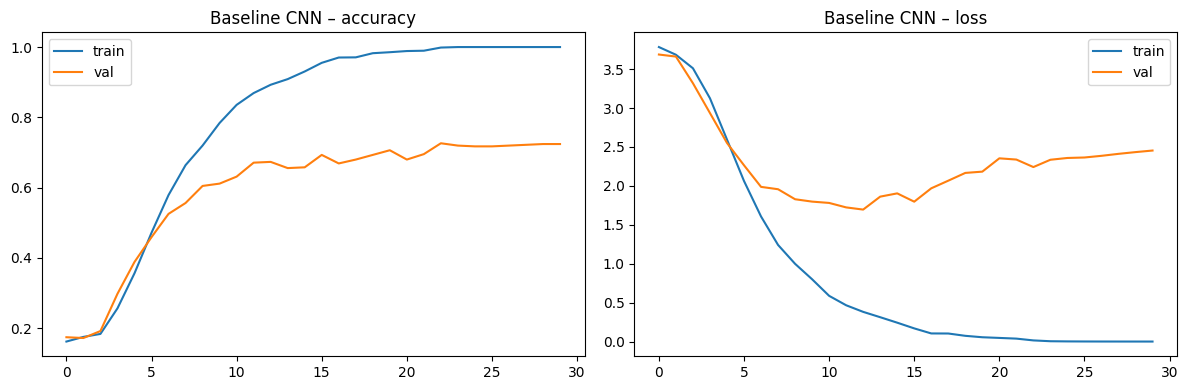

Baseline CNN: test accuracy=0.692 | macro F1=0.599 | weighted F1=0.682


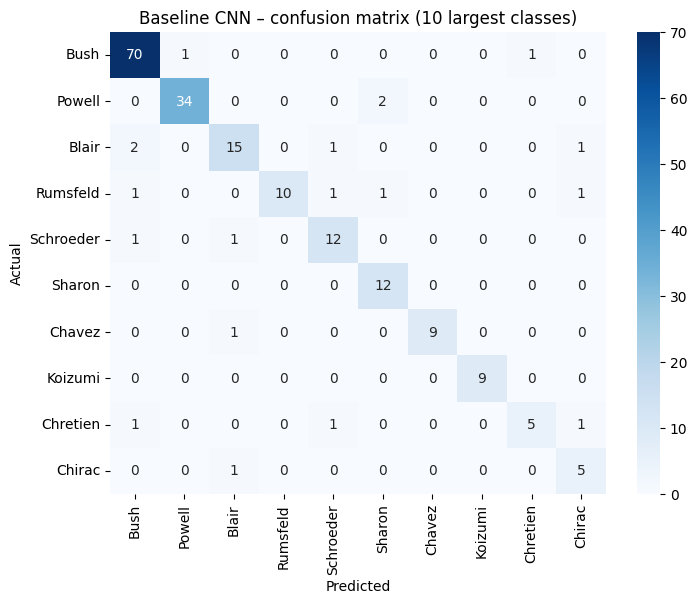

,precision,recall,f1-score,support
George W Bush,0.813953,0.875000,0.843373,80.0
Colin Powell,0.871795,0.944444,0.906667,36.0
Tony Blair,0.681818,0.681818,0.681818,22.0
Donald Rumsfeld,0.833333,0.555556,0.666667,18.0
Gerhard Schroeder,0.666667,0.705882,0.685714,17.0
Ariel Sharon,0.631579,1.000000,0.774194,12.0
Hugo Chavez,0.818182,0.818182,0.818182,11.0
Junichiro Koizumi,0.500000,1.000000,0.666667,9.0
Jean Chretien,0.833333,0.625000,0.714286,8.0
Jacques Chirac,0.416667,0.625000,0.500000,8.0


In [12]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history["accuracy"], label="train"); ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title(f"{title} – accuracy"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train"); ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title(f"{title} – loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

def evaluate(model, name):
    pred = model.predict(X_test, verbose=0).argmax(axis=1)
    acc = accuracy_score(y_test, pred)
    f1m = f1_score(y_test, pred, average="macro")
    f1w = f1_score(y_test, pred, average="weighted")
    print(f"{name}: test accuracy={acc:.3f} | macro F1={f1m:.3f} | weighted F1={f1w:.3f}")
    rep = classification_report(y_test, pred, labels=range(n_classes),
                                target_names=classes, zero_division=0, output_dict=True)
    rep_df = pd.DataFrame(rep).T.iloc[:n_classes].sort_values("support", ascending=False)
    # confusion matrix for the 10 people with most test images
    top10 = [cls_index[n] for n in rep_df.index[:10]]
    cm = confusion_matrix(y_test, pred, labels=top10)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[classes[i].split()[-1] for i in top10],
                yticklabels=[classes[i].split()[-1] for i in top10])
    plt.title(f"{name} – confusion matrix (10 largest classes)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()
    return {"model": name, "accuracy": acc, "macro_f1": f1m, "weighted_f1": f1w}, rep_df

plot_history(hist_v1, "Baseline CNN")
res_v1, rep_v1 = evaluate(model_v1, "Baseline CNN")
rep_v1[["precision", "recall", "f1-score", "support"]].head(10)

**Interpretation:** the baseline reached **100% training accuracy** within a few epochs while validation accuracy plateaued at about **72%** and validation loss kept *rising* (to about 2.45). This is a textbook case of **overfitting**: with only about 2,100 training faces and no regularisation, the network memorised the training images. On the test set it scored **69.2% accuracy** but only **0.599 macro F1**. The gap between the two shows that it does much better on people with many photos (George W Bush F1 0.84, Colin Powell 0.91) than on people with few photos, which confirms the class-imbalance problem from the EDA.

## 6. Retrained CNN – addressing the baseline's weaknesses
The baseline reached 100% training accuracy but only about 72% validation accuracy, which is clear **overfitting**: it memorised the 2,116 training faces instead of learning features that generalise. The retrained model keeps the same convolutional backbone so the comparison is fair, and changes only what targets that problem:

| Change | Problem it targets |
|---|---|
| Data augmentation (random horizontal flip, small rotation, zoom and shift), applied only during training | Overfitting, and pose/framing variation at a real entrance camera |
| Dropout (0.3 after the conv blocks, 0.5 before the output) | Overfitting – stops the network relying on a few memorised features |
| L2 weight penalty on the dense layer | Overfitting – keeps weights small |
| Larger dense layer (256 units) | Restores capacity lost to dropout |
| Mild class weights (square root of balanced weights) | Imbalance – the model otherwise favours people with many photos (e.g. George W Bush) |
| Early stopping on validation accuracy (best weights restored) + learning-rate halving on plateau | Stops at the best validation point instead of a fixed epoch count |

*Note:* a first attempt that also added batch normalisation and global average pooling learned very slowly (validation accuracy around 10–17% after 10 epochs at 23 s per epoch), so it was dropped in favour of this simpler design.

In [14]:
cw = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_train)
class_weights = {i: float(np.sqrt(w)) for i, w in enumerate(cw)}

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.05, 0.05),
], name="augmentation")

def build_improved():
    m = keras.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        augment,
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model_v2 = build_improved()
model_v2.summary()
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5),
]
hist_v2 = model_v2.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=80, batch_size=32, class_weight=class_weights,
                       callbacks=callbacks, verbose=2)
model_v2.save("model_v2_improved.keras")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)            │ (None, 62, 47, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 62, 47, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 31, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 31, 23, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 15, 11, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 15, 11, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 7, 5, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 7, 5, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 4480)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │       1,147,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 62)                  │          15,934 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,255,742 (4.79 MB)

 Trainable params: 1,255,742 (4.79 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
67/67 - 14s - 202ms/step - accuracy: 0.1446 - loss: 3.7637 - val_accuracy: 0.1744 - val_loss: 3.9354 - learning_rate: 0.0010
Epoch 2/80
67/67 - 7s - 99ms/step - accuracy: 0.1664 - loss: 3.7335 - val_accuracy: 0.1744 - val_loss: 3.8371 - learning_rate: 0.0010
Epoch 3/80
67/67 - 6s - 97ms/step - accuracy: 0.1649 - loss: 3.7003 - val_accuracy: 0.1810 - val_loss: 3.7770 - learning_rate: 0.0010
Epoch 4/80
67/67 - 5s - 77ms/step - accuracy: 0.1697 - loss: 3.5913 - val_accuracy: 0.1810 - val_loss: 3.5791 - learning_rate: 0.0010
Epoch 5/80
67/67 - 7s - 108ms/step - accuracy: 0.1583 - loss: 3.4812 - val_accuracy: 0.2009 - val_loss: 3.4132 - learning_rate: 0.0010
Epoch 6/80
67/67 - 8s - 124ms/step - accuracy: 0.1645 - loss: 3.3607 - val_accuracy: 0.2163 - val_loss: 3.2801 - learning_rate: 0.0010
Epoch 7/80
67/67 - 7s - 111ms/step - accuracy: 0.1701 - loss: 3.2395 - val_accuracy: 0.2539 - val_loss: 3.1027 - learning_rate: 0.0010
Epoch 8/80
67/67 - 7s - 109ms/step - accuracy: 0.1730 - l

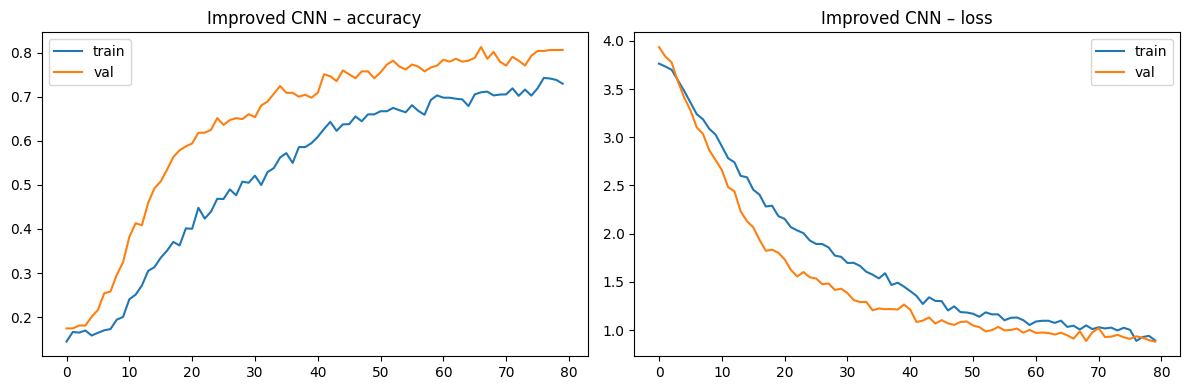

Improved CNN: test accuracy=0.793 | macro F1=0.743 | weighted F1=0.792


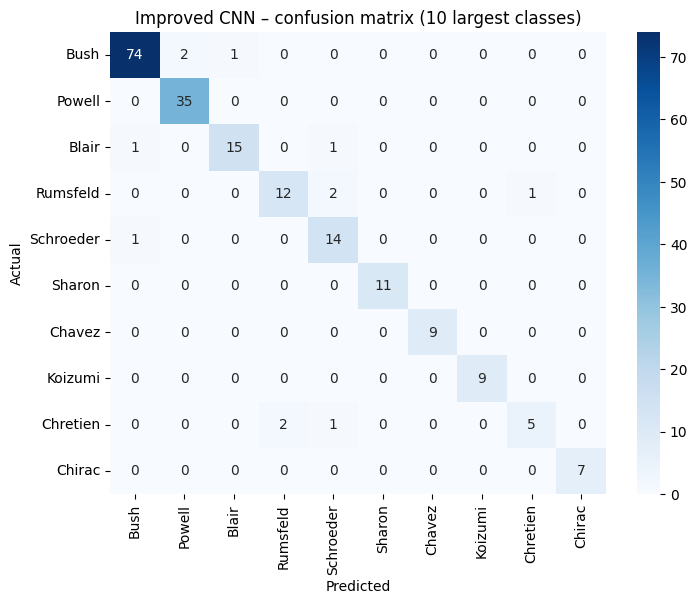

,precision,recall,f1-score,support
George W Bush,0.925000,0.925000,0.925000,80.0
Colin Powell,0.897436,0.972222,0.933333,36.0
Tony Blair,0.681818,0.681818,0.681818,22.0
Donald Rumsfeld,0.750000,0.666667,0.705882,18.0
Gerhard Schroeder,0.700000,0.823529,0.756757,17.0
Ariel Sharon,1.000000,0.916667,0.956522,12.0
Hugo Chavez,0.900000,0.818182,0.857143,11.0
Junichiro Koizumi,0.692308,1.000000,0.818182,9.0
Jean Chretien,0.714286,0.625000,0.666667,8.0
Jacques Chirac,0.875000,0.875000,0.875000,8.0


In [15]:
plot_history(hist_v2, "Improved CNN")
res_v2, rep_v2 = evaluate(model_v2, "Improved CNN")
rep_v2[["precision", "recall", "f1-score", "support"]].head(10)

## 7. Model comparison

,accuracy,macro_f1,weighted_f1,trainable_params,epochs_run
model,,,,,
Baseline CNN,0.692,0.599,0.682,674238,30
Improved CNN,0.793,0.743,0.792,1255742,80


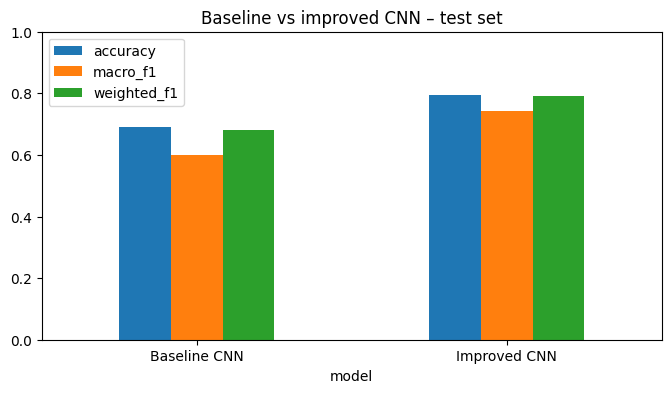

+-------------------+---------------+------------+
|      avg_f1_change|people_improved|people_worse|
+-------------------+---------------+------------+
|0.14376240207626975|             47|           8|
+-------------------+---------------+------------+



In [16]:
comp = pd.DataFrame([res_v1, res_v2]).set_index("model").round(3)
comp["trainable_params"] = [model_v1.count_params(), model_v2.count_params()]
comp["epochs_run"] = [len(hist_v1.history["loss"]), len(hist_v2.history["loss"])]
display(comp)

comp[["accuracy", "macro_f1", "weighted_f1"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Baseline vs improved CNN – test set"); plt.ylim(0, 1); plt.show()

# Spark summary of per-person F1 change (Spark used for analysis of results too)
f1_change = pd.DataFrame({"person": rep_v1.index,
                          "f1_v1": rep_v1["f1-score"].values}).merge(
            pd.DataFrame({"person": rep_v2.index, "f1_v2": rep_v2["f1-score"].values}), on="person")
sf = spark.createDataFrame(f1_change).withColumn("delta", F.col("f1_v2") - F.col("f1_v1"))
sf.agg(F.avg("delta").alias("avg_f1_change"),
       F.sum((F.col("delta") > 0).cast("int")).alias("people_improved"),
       F.sum((F.col("delta") < 0).cast("int")).alias("people_worse")).show()

### 7.1 Sample predictions
Green title = correct, red = wrong. Useful for the report's error analysis (e.g. side profiles, poor lighting, sunglasses).

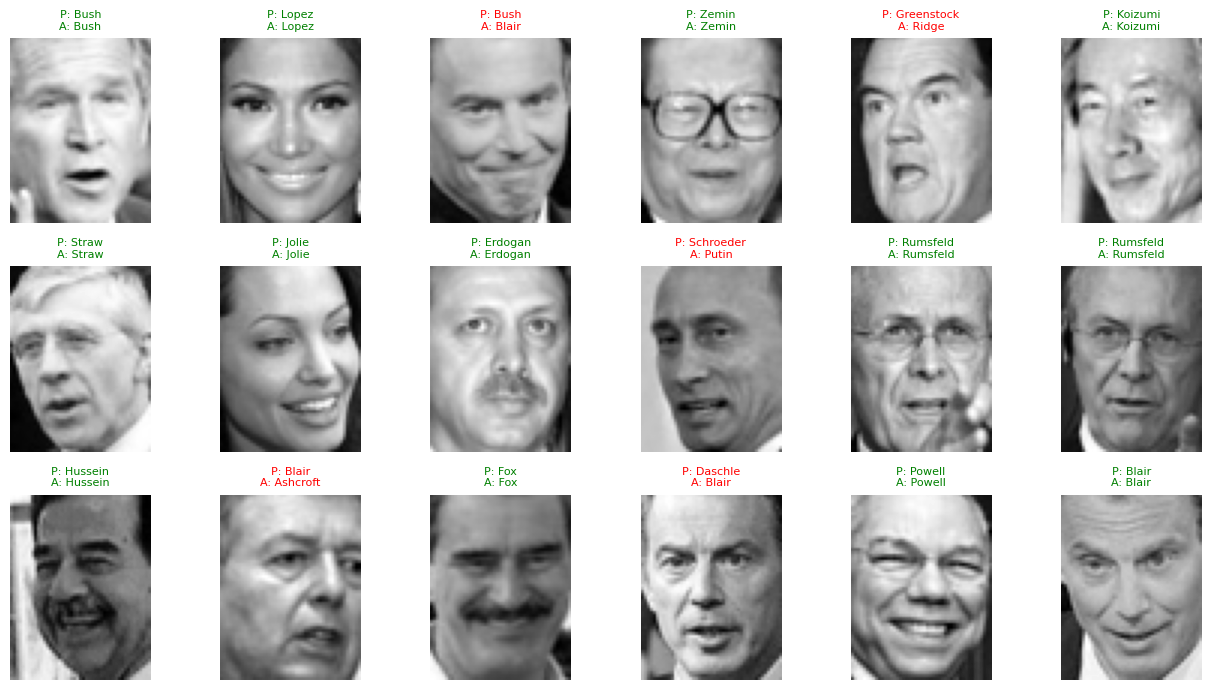

In [17]:
best = model_v2 if res_v2["macro_f1"] >= res_v1["macro_f1"] else model_v1
pred = best.predict(X_test, verbose=0).argmax(axis=1)
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for a, i in zip(axes.ravel(), np.random.choice(len(X_test), 18, replace=False)):
    a.imshow(X_test[i].squeeze(), cmap="gray"); a.axis("off")
    ok = pred[i] == y_test[i]
    a.set_title(f"P: {classes[pred[i]].split()[-1]}\nA: {classes[y_test[i]].split()[-1]}",
                fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

## 8. Conclusion
| Model | Test accuracy | Macro F1 | Weighted F1 |
|---|---|---|---|
| Baseline CNN | 0.692 | 0.599 | 0.682 |
| Improved CNN | **0.793** | **0.743** | **0.792** |

- **The improved model is better on every metric:** +10.1 points accuracy and +0.144 macro F1. Spark analysis of per-person F1 shows **47 of 62 people improved** and only 8 got worse.
- **Why it worked:** in the baseline, training accuracy hit 100% while validation loss rose. In the improved model, augmentation and dropout kept training accuracy (about 70%) *below* validation accuracy (about 80%) and validation loss kept falling. In other words, it generalised instead of memorising. The bigger rise in macro F1 than in accuracy shows the mild class weights helped the under-represented people most.
- **Remaining weaknesses:** people with fewer photos (e.g. Jean Chretien, Tony Blair, about 0.67–0.68 F1) are still confused with similar-looking faces. Training also used the full 80 epochs, so slightly longer training might gain a little more.
- **Deployment view for the publisher:** this is a closed-set classifier, so it only recognises people it was trained on. A real entrance system would need: a face-detection step before classification, a confidence threshold to flag "unknown" visitors, several enrolment photos per staff member taken under the entrance lighting, and POPIA-compliant consent, because facial images are biometric (special personal) information.
- **Future work:** transfer learning from a pretrained face-embedding model (e.g. FaceNet), colour images, and more photos per person.

## Code attribution
- The notebook structure and code were developed with the help of an AI assistant (Claude, Anthropic, 2026). I reviewed, ran, debugged and adapted all of it, and I can explain each step.
- Standard usage patterns follow the official documentation: scikit-learn `fetch_lfw_people`, `train_test_split` and metrics (Pedregosa et al., 2011); Keras `Sequential`, augmentation layers and callbacks (Chollet et al., 2015); and the PySpark DataFrame API (Apache Software Foundation, 2026).
- The dataset is downloaded from the LFW site via scikit-learn: http://vis-www.cs.umass.edu/lfw/

## References
Anthropic. 2026. *Claude* [AI assistant]. Available at: https://claude.ai [Accessed 18 November 2026].

Apache Software Foundation. 2026. *PySpark 4.2 documentation*. Available at: https://spark.apache.org/docs/latest/api/python/ [Accessed 18 November 2026].

Chollet, F. et al. 2015. *Keras*. Available at: https://keras.io [Accessed 18 November 2026].

Huang, G.B., Ramesh, M., Berg, T. and Learned-Miller, E. 2007. *Labeled Faces in the Wild: A database for studying face recognition in unconstrained environments*. Technical Report 07-49. Amherst: University of Massachusetts.

Pedregosa, F. et al. 2011. Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12: 2825–2830.

South Africa. 2013. *Protection of Personal Information Act 4 of 2013*. Pretoria: Government Printer.

University of Massachusetts Amherst. n.d. *Labeled Faces in the Wild Home*. Available at: http://vis-www.cs.umass.edu/lfw/ [Accessed 18 November 2026].

In [18]:
spark.stop()